# Project 2: Deep Neural Networks for Estimating the m-Height of Analog Codes

## The Model

- **One network per setting** (a mixture of experts). Each test sample is sent to the network of its $(k, m)$.
- **Inputs and outputs:** the matrix $P$ (zero-padded to $6 \times 5$) and $(n, k, m)$ go in. The network outputs $z = \log_2 \hat y \in [0, 100]$, and the only post-processing is $\hat y = 2^z$. Predicting the logarithm makes the training loss (mean squared error) equal to the grading cost, and guarantees every prediction is finite and $\ge 1$.
- **Networks:** every network treats each entry of $P$ as a token in a grid. A **row/column network** mixes every entry with the means of its row and column, and a **transformer** lets every entry attend to the entries of its row and column. Neither depends on the order of the rows and columns of $P$, just like the m-height (section 4).
- **Training data:** millions of new data were generated offline and we generated two kinds of data:
  - independent random matrices, sampled with the same per-matrix scales as the provided data;
  - **augmented provided** matrices, made by adding small integer noise ($\pm 2$) to every entry of provided training matrices. The provided matrices come in tight clusters, so these cover the neighbourhoods where training matrices lie.
- **Training:** each network is trained first on all of its setting's data (phase 1) and, depending on its version, then fine-tuned mainly on the provided and augmented provided rows (phase 2; section 5). Validation and test use only provided matrices, which were never used in training.
- **Versions:** the networks were developed in versions V1–V7 (below). After training, each setting uses the version with the lowest validation cost (section 7).

## Network Versions

Each version changes one thing from an earlier one. All versions are trained on the same data (section 3) and scored on the same validation rows.

| Version | Change | Architecture | Size | Optimiser | Phase 1 | Phase 2 (fine-tuning) | Trained for |
|---|---|---|---|---|---|---|---|
| **V1** | starting point | row/column network | width 192, 5 blocks; 1.7 M parameters | `adam_plateau` | 30 epochs from 1e-3 | 60 epochs from 3e-4 | all 9 settings |
| **V2** | attention instead of row and column means | transformer | width 128, 4 blocks, 4 heads; 0.8 M parameters | `adam_plateau` | 30 epochs from 1e-3 | 60 epochs from 3e-4 | all 9 settings |
| **V4** | a larger transformer for the settings with $m = n - k$ | transformer | width 192, 6 blocks, 8 heads; 2.7 M parameters | `adam_plateau` | 30 epochs from 1e-3 | 60 epochs from 3e-4 | (9, 4, 5), (9, 5, 4), (9, 6, 3) |
| **V5** | warm-up and cosine learning rate; no fine-tuning | as V4 | as V4 | `adamw_cosine` | 30 epochs, peak 5e-4 | none | (9, 4, 5), (9, 5, 4) |
| **V6** | a schedule twice as long | as V4 | as V4 | `adamw_cosine` | 60 epochs, peak 5e-4, no early stopping | none | (9, 4, 5), (9, 5, 4) |
| **V7** | twice as long again | as V4 | as V4 | `adamw_cosine` | 120 epochs, peak 5e-4, no early stopping | none | (9, 4, 5), (9, 5, 4) |

V3 trained no new network: it introduced choosing the network of each setting by its validation cost (section 7).

## Outline

1. Configuration.
2. Provided data and the data split.
3. Exact training-data generation, including a check against the provided labels.
4. The network architectures.
5. Training every version.
6. Training and validation loss curves.
7. Choosing the network for each setting.
8. The final model and its validation and test performance.
9. **Final cell:** load the trained model and predict m-heights for a test file.


In [1]:
# Install dependencies (Google Colab only; elsewhere the project environment is used).

import sys

if "google.colab" in sys.modules:
    %pip install -q "numpy>=2,<3" "tensorflow==2.21.0" "keras==3.15.1" scipy matplotlib


## 1. Configuration

All settings can be changed through environment variables, which is how the batch runs were configured. The defaults below are the configuration used for the submitted results. TensorFlow is imported in section 4, after the data-generation code, whose worker processes are started by forking.

| Setting | Default | Environment variable |
|---|---|---|
| Output directory | `artifacts/submission` | `MHEIGHT_RUN` |
| Settings to train (`k-m` list) | all 9 | `MHEIGHT_SETTINGS` |
| Train the networks (otherwise load trained ones) | `1` | `MHEIGHT_TRAIN` |
| Networks (random seeds) averaged per setting | 1 | `MHEIGHT_SEEDS` |
| Train/validation/test split: `80-10-10` or `60-20-20` (section 2) | `80-10-10` | `MHEIGHT_SPLIT` |
| Use the augmented provided rows (section 3.4) | `1` | `MHEIGHT_AUGMENTED_DATA` |
| Fine-tuning learning rate | 3e-4 | `MHEIGHT_FINETUNE_LR` |
| Batch size | 4096 | `MHEIGHT_BATCH` |
| Network versions to train or load (table at the top): `all`, or a list such as `V6,V7` | `all` | `MHEIGHT_VERSIONS` |
| One part of every version's recipe, overridden for experiments: | | |
| &nbsp;&nbsp; network architecture: `rowcol`, `transformer` or `transformer_large` | | `MHEIGHT_ARCH` |
| &nbsp;&nbsp; optimiser: `adam_plateau` or `adamw_cosine` | | `MHEIGHT_OPTIMIZER` |
| &nbsp;&nbsp; phase-1 learning rate | | `MHEIGHT_LR` |
| &nbsp;&nbsp; phase-1 epochs | | `MHEIGHT_PHASE1_EPOCHS` |
| &nbsp;&nbsp; fine-tuning epochs (0 = phase 1 only) | | `MHEIGHT_FINETUNE_EPOCHS` |
| &nbsp;&nbsp; early-stopping patience in epochs (0 = off) | | `MHEIGHT_PATIENCE` |
| Dropout inside each block | 0 | `MHEIGHT_DROPOUT` |
| Share of independent random rows in fine-tuning (section 5) | 0.25 | `MHEIGHT_FINETUNE_RANDOM` |
| TF32 matrix multiplications during GPU training (section 4) | `1` | `MHEIGHT_TF32` |
| Cap on generated rows per setting (0 = all; for quick tests) | 0 | `MHEIGHT_MAX_ROWS` |


In [2]:
import hashlib
import json
import math
import multiprocessing as mp
import os
import pickle
import shutil
import time
from itertools import combinations, product
from pathlib import Path

import numpy as np

N = 9
SETTINGS_ALL = [(9, k, m) for k in (4, 5, 6) for m in range(2, 9 - k + 1)]
_chosen = os.environ.get("MHEIGHT_SETTINGS", "all")
SETTINGS = SETTINGS_ALL if _chosen == "all" else [(9, *map(int, s.split("-"))) for s in _chosen.split(",")]
RUN_DIR = Path("artifacts") / os.environ.get("MHEIGHT_RUN", "submission")
RUN_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path("data")
TRAIN = os.environ.get("MHEIGHT_TRAIN", "1") == "1"
SEEDS = int(os.environ.get("MHEIGHT_SEEDS", 1))
AUGMENTED_DATA = os.environ.get("MHEIGHT_AUGMENTED_DATA", "1") == "1"
SPLIT = os.environ.get("MHEIGHT_SPLIT", "80-10-10")
if SPLIT not in ("60-20-20", "80-10-10"):
    raise ValueError("MHEIGHT_SPLIT must be 60-20-20 or 80-10-10")
FINETUNE_LEARNING_RATE = float(os.environ.get("MHEIGHT_FINETUNE_LR", 3e-4))
BATCH_SIZE = int(os.environ.get("MHEIGHT_BATCH", 4096))
# Network versions (table at the top): architecture, optimiser, phase-1 learning rate and epochs, fine-tuning epochs
# (0 = phase 1 only), early-stopping patience (0 = off), and the settings the version is trained for.
HARD = [(9, 4, 5), (9, 5, 4)]
VERSIONS = {
    "V1": dict(arch="rowcol", optimizer="adam_plateau", lr=1e-3, phase1=30, finetune=60, patience=8, settings=SETTINGS_ALL),
    "V2": dict(arch="transformer", optimizer="adam_plateau", lr=1e-3, phase1=30, finetune=60, patience=8, settings=SETTINGS_ALL),
    "V4": dict(arch="transformer_large", optimizer="adam_plateau", lr=1e-3, phase1=30, finetune=60, patience=8,
               settings=HARD + [(9, 6, 3)]),
    "V5": dict(arch="transformer_large", optimizer="adamw_cosine", lr=5e-4, phase1=30, finetune=0, patience=8, settings=HARD),
    "V6": dict(arch="transformer_large", optimizer="adamw_cosine", lr=5e-4, phase1=60, finetune=0, patience=0, settings=HARD),
    "V7": dict(arch="transformer_large", optimizer="adamw_cosine", lr=5e-4, phase1=120, finetune=0, patience=0, settings=HARD),
}
_versions = os.environ.get("MHEIGHT_VERSIONS", "all")
RUN_VERSIONS = list(VERSIONS) if _versions == "all" else _versions.split(",")
for key, variable, cast in (("arch", "MHEIGHT_ARCH", str), ("optimizer", "MHEIGHT_OPTIMIZER", str), ("lr", "MHEIGHT_LR", float),
                            ("phase1", "MHEIGHT_PHASE1_EPOCHS", int), ("finetune", "MHEIGHT_FINETUNE_EPOCHS", int),
                            ("patience", "MHEIGHT_PATIENCE", int)):
    if os.environ.get(variable):
        for recipe in VERSIONS.values():
            recipe[key] = cast(os.environ[variable])
TRANSFORMER = {"transformer": (128, 4, 4), "transformer_large": (192, 6, 8)}   # width, blocks, attention heads
ROWCOL_WIDTH, ROWCOL_BLOCKS = 192, 5
DROPOUT = float(os.environ.get("MHEIGHT_DROPOUT", 0))
FINETUNE_RANDOM = float(os.environ.get("MHEIGHT_FINETUNE_RANDOM", 0.25))
TF32 = os.environ.get("MHEIGHT_TF32", "1") == "1"
MAX_ROWS = int(os.environ.get("MHEIGHT_MAX_ROWS", 0))
SEED = 636
MAX_LOG2_HEIGHT = 100.0
print(f"Run directory: {RUN_DIR}; settings: {SETTINGS}; train: {TRAIN}; seeds: {SEEDS}; split: {SPLIT}; "
      f"augmented provided data: {AUGMENTED_DATA}")
for v in RUN_VERSIONS:
    r = VERSIONS[v]
    print(f"  {v}: {r['arch']}, {r['optimizer']}, phase 1: {r['phase1']} epochs from {r['lr']:g}, fine-tuning: {r['finetune']} epochs, "
          f"early-stopping patience: {r['patience'] or 'off'}; trained for {len(r['settings'])} settings")


Run directory: artifacts/p2_v7_all; settings: [(9, 4, 2), (9, 4, 3), (9, 4, 4), (9, 4, 5), (9, 5, 2), (9, 5, 3), (9, 5, 4), (9, 6, 2), (9, 6, 3)]; train: False; seeds: 1; split: 80-10-10; augmented provided data: True
  V1: rowcol, adam_plateau, phase 1: 30 epochs from 0.001, fine-tuning: 60 epochs, early-stopping patience: 8; trained for 9 settings
  V2: transformer, adam_plateau, phase 1: 30 epochs from 0.001, fine-tuning: 60 epochs, early-stopping patience: 8; trained for 9 settings
  V4: transformer_large, adam_plateau, phase 1: 30 epochs from 0.001, fine-tuning: 60 epochs, early-stopping patience: 8; trained for 3 settings
  V5: transformer_large, adamw_cosine, phase 1: 30 epochs from 0.0005, fine-tuning: 0 epochs, early-stopping patience: 8; trained for 2 settings
  V6: transformer_large, adamw_cosine, phase 1: 60 epochs from 0.0005, fine-tuning: 0 epochs, early-stopping patience: off; trained for 2 settings
  V7: transformer_large, adamw_cosine, phase 1: 120 epochs from 0.0005, 

## 2. The Provided Data and the Split

The provided training set consists of two pickled lists: 4,321,835 samples `[n, k, m, P]` and their m-heights. The test set will have the same format.
- **Matrix-level split:** the same matrix $P$ appears once for each $m$ with a finite m-height. A random split of rows would put the same matrix in both training and evaluation and make the results look better than they are. Instead, a seeded hash of $(n, k, P)$ assigns each distinct matrix, with all its rows, to **training, validation or test** in the proportions 80/10/10% (60/20/20% with `MHEIGHT_SPLIT=60-20-20`). The 80% gives the networks as many provided rows as possible, while about 430,000 rows each remain for validation and test, enough for stable estimates.
- Training rows are used to fit the networks, and as seeds for the augmented provided data. Validation rows choose the best epoch of every training phase and the network version of each setting (section 7). Test rows are used only for the final report in section 8.


In [3]:
NUMPY_MAJOR = int(np.__version__.split(".")[0])


class NumpyCompatUnpickler(pickle.Unpickler):
    # Pickles written with NumPy 2 reference numpy._core; NumPy 1.x only provides numpy.core.
    def find_class(self, module, name):
        if NUMPY_MAJOR < 2 and module.startswith("numpy._core"):
            module = "numpy.core" + module[len("numpy._core"):]
        return super().find_class(module, name)


def load_pickle(path):
    with open(path, "rb") as file:
        return NumpyCompatUnpickler(file).load()


features = load_pickle(DATA_DIR / "CSCE-636-Project-2-Train-n_k_m_P")
labels = np.asarray(load_pickle(DATA_DIR / "CSCE-636-Project-2-Train-mHeights"), dtype=np.float64)
if len(features) != len(labels) or not np.isfinite(labels).all() or labels.min() < 1:
    raise ValueError("Expected aligned lists of samples and finite m-heights >= 1")
print(f"Provided data: {len(features):,} samples")
for index in range(3):
    n, k, m, P = features[index]
    print(f"sample {index}: n={n}, k={k}, m={m}, m-height={labels[index]:.4f}\n{P}")


def matrix_partitions(samples, seed):
    """0/1/2 = train/validation/test, decided per distinct matrix by a keyed hash."""
    parts, cache, key = np.empty(len(samples), dtype=np.uint8), {}, int(seed).to_bytes(8, "little")
    for i, (n, k, m, P) in enumerate(samples):
        ident = (int(n), int(k), id(P))
        if ident not in cache:
            payload = bytes((int(n), int(k))) + np.asarray(P, dtype="<f8").tobytes(order="C")
            bucket = int.from_bytes(hashlib.blake2b(payload, digest_size=8, key=key).digest(), "little") % 10
            train_cut, validation_cut = (6, 8) if SPLIT == "60-20-20" else (8, 9)
            cache[ident] = 0 if bucket < train_cut else (1 if bucket < validation_cut else 2)
        parts[i] = cache[ident]
    return parts


partition = matrix_partitions(features, SEED)
setting_of = np.array([SETTINGS_ALL.index((int(n), int(k), int(m))) for n, k, m, _ in features], dtype=np.int8)
provided_P = np.zeros((len(features), 6, 5), dtype=np.float32)
for i, (n, k, m, P) in enumerate(features):
    provided_P[i, :k, :n - k] = P
print("\n(n, k, m)      train   validation      test")
for g, s in enumerate(SETTINGS_ALL):
    c = [int(np.sum((setting_of == g) & (partition == p))) for p in (0, 1, 2)]
    print(f"{str(s):12s} {c[0]:8,d} {c[1]:12,d} {c[2]:9,d}")


Provided data: 4,321,835 samples
sample 0: n=9, k=4, m=5, m-height=4014.8750
[[  4.  11.   6.  30. -14.]
 [ 20. -24. -11. -21.   3.]
 [ 17. -20.  21. -16.   6.]
 [ 22.   9.  16.  33.  21.]]
sample 1: n=9, k=4, m=3, m-height=31.7636
[[ -1.   5.   7.  -6.   3.]
 [-14.   6. -13.   8. -11.]
 [  4.   5.   4.   3.  -8.]
 [  5.  -6.   5.  -5.  14.]]
sample 2: n=9, k=4, m=3, m-height=45.2000
[[ -2.   4. -10.   7. -11.]
 [-18. -16.  -8.   3.   5.]
 [ -8.  16.  -6.  14.  13.]
 [ 18.  16. -10.   7. -16.]]



(n, k, m)      train   validation      test
(9, 4, 2)     616,759       76,669    76,914
(9, 4, 3)     614,875       76,431    76,672
(9, 4, 4)     595,662       73,970    74,246
(9, 4, 5)     443,892       54,840    55,178
(9, 5, 2)     302,151       37,670    38,021
(9, 5, 3)     295,208       36,793    37,151
(9, 5, 4)     220,666       27,354    27,581
(9, 6, 2)     215,034       26,836    27,088
(9, 6, 3)     155,241       19,355    19,578


## 3. Exact Training-Data Generation

More training data were genearted using an equivalent but much faster exact algorithm compared to the given LP algorithm.

### 3.1 Exact labels

`vertex_heights` computes all m-heights of a batch of matrices exactly, without an LP solver.
- **Vertices:** every linear program in the m-height computation has its optimum at a vertex of its feasible region. Each vertex corresponds to $k$ columns $T$ of $G$ and a sign vector $s$, giving the codeword $c = s\,G_T^{-1}G$.
- **The m-height:** the function enumerates all of these vertices. The m-height is the largest $\max_t |c_t|$ among vertex codewords with at most $m$ entries larger than 1 in magnitude.
- **Infinite cases:** rows whose m-height is infinite (some $n-m$ columns of $G$ do not span $\mathbb R^k$) are dropped, as in the provided data and the test set.

`closed_form_heights` is a faster special case for $m = n-k$: the largest $\lVert G_T^{-1} g_j \rVert_1$ over $k$-column sets $T$ and columns $j \notin T$.

The next cell checks both functions against the provided labels. They only create training labels.


In [4]:
MAX_ENTRY = 100
COLUMN_SETS = {k: list(combinations(range(N), k)) for k in (4, 5, 6)}
SIGNS = {k: np.array([(1,) + s for s in product((1, -1), repeat=k - 1)], dtype=np.float64) for k in (4, 5, 6)}


def vertex_heights(P):
    """m-heights for m = 0..n-k of a batch P (B, k, n-k) by LP vertex enumeration; inf where infinite."""
    batch, k = P.shape[0], P.shape[1]
    G = np.concatenate((np.broadcast_to(np.eye(k), (batch, k, k)), P), axis=2)
    best = np.zeros((batch, N - k + 1))
    for T in COLUMN_SETS[k]:
        block = G[:, :, T]
        ok = np.abs(np.linalg.det(block)) >= 0.5          # integer P: nonsingular => |det| >= 1
        X = np.linalg.solve(np.where(ok[:, None, None], block, np.eye(k)), G)
        C = np.abs(np.einsum("sk,bkn->bsn", SIGNS[k], X))  # |codeword| at each vertex
        above, top = (C > 1 + 1e-9).sum(axis=2), C.max(axis=2)
        for m in range(1, N - k + 1):
            best[:, m] = np.maximum(best[:, m], np.where(ok, np.where(above <= m, top, 0.0).max(axis=1), 0.0))
    best[:, 0] = 1.0
    for m in range(1, N - k + 1):                          # infinite: some n-m columns of rank < k
        for R in combinations(range(N), N - m):
            best[np.linalg.matrix_rank(G[:, :, list(R)]) < k, m] = np.inf
    return best


def closed_form_heights(P):
    """h_{n-k} = max over k-column sets T and j not in T of ||G_T^{-1} g_j||_1; inf if some G_T is singular."""
    batch, k = P.shape[0], P.shape[1]
    G = np.concatenate((np.broadcast_to(np.eye(k), (batch, k, k)), P), axis=2)
    best, singular = np.zeros(batch), np.zeros(batch, dtype=bool)
    for T in COLUMN_SETS[k]:
        rest = [j for j in range(N) if j not in T]
        block = G[:, :, T]
        bad = np.abs(np.linalg.det(block)) < 0.5
        singular |= bad
        X = np.linalg.solve(np.where(bad[:, None, None], np.eye(k), block), G[:, :, rest])
        best = np.maximum(best, np.abs(X).sum(axis=1).max(axis=1))
    best[singular] = np.inf
    return best


# Check: both algorithms reproduce the provided labels.
rng = np.random.default_rng(0)
for g, (n, k, m) in enumerate(SETTINGS_ALL):
    idx = rng.choice(np.flatnonzero(setting_of == g), size=300, replace=False)
    Pk = np.stack([features[i][3] for i in idx]).astype(np.float64)
    err = np.abs(np.log2(vertex_heights(Pk)[:, m]) - np.log2(labels[idx])).max()
    line = f"{(n, k, m)}: vertex enumeration vs provided labels, max |log2 difference| = {err:.1e}"
    if m == n - k:
        line += f"; closed form: {np.abs(np.log2(closed_form_heights(Pk)) - np.log2(labels[idx])).max():.1e}"
    print(line)


(9, 4, 2): vertex enumeration vs provided labels, max |log2 difference| = 7.1e-15


(9, 4, 3): vertex enumeration vs provided labels, max |log2 difference| = 3.6e-15


(9, 4, 4): vertex enumeration vs provided labels, max |log2 difference| = 4.3e-13


(9, 4, 5): vertex enumeration vs provided labels, max |log2 difference| = 4.2e-12; closed form: 4.2e-12


(9, 5, 2): vertex enumeration vs provided labels, max |log2 difference| = 2.7e-15


(9, 5, 3): vertex enumeration vs provided labels, max |log2 difference| = 1.6e-14


(9, 5, 4): vertex enumeration vs provided labels, max |log2 difference| = 4.6e-12; closed form: 4.6e-12


(9, 6, 2): vertex enumeration vs provided labels, max |log2 difference| = 1.8e-15


(9, 6, 3): vertex enumeration vs provided labels, max |log2 difference| = 4.8e-13; closed form: 4.8e-13


### 3.2 Sampling new matrices

The provided matrices have integer entries. Each matrix has its own scale: its largest $|P_{ij}|$ varies widely, from about 9 at the 5th percentile to 81 at the median. New matrices copy this.
- **Scale:** for each $k$, a scale $a$ is drawn from the histogram of per-matrix $\max|P_{ij}|$ in the provided **training-split** data.
- **Entries:** integers drawn uniformly from $[-a, a]$.
- **Rejection:** matrices with an all-zero column are redrawn, since the specification excludes all-zero columns of $G$.

Every matrix contributes its finite rows $m = 2, 3, \dots$. Seeds depend only on the run seed and a chunk index, so the files are reproducible regardless of the number of worker processes.

### 3.3 Generating the files

Generation runs only if the files are missing; with 128 CPU cores it takes a few minutes. The files used for the results below are:
- `CSCE-636-Project-2-Train-RandomExact.npz`: 5 million matrices per $k$, about 40 million rows, all settings, by vertex enumeration;
- `CSCE-636-Project-2-Train-RandomExact-MaxM.npz`: 10 million rows for each $m = n-k$ setting, by the closed form.


In [5]:
def empirical_scales(samples):
    """Per k, the histogram of per-matrix max |P| in the given samples (every matrix has an m=2 row)."""
    counts = {k: [0] * (MAX_ENTRY + 1) for k in (4, 5, 6)}
    for n, k, m, P in samples:
        if m == 2:
            counts[k][int(np.max(np.abs(P)))] += 1
    return {str(k): row for k, row in counts.items()}


def sample_matrix(rng, k, scale_counts):
    """Integer P with a per-matrix scale drawn from the provided data; no all-zero column."""
    weights = np.asarray(scale_counts, dtype=np.float64)
    weights[0] = 0.0
    while True:
        a = int(rng.choice(MAX_ENTRY + 1, p=weights / weights.sum()))
        P = rng.integers(-a, a + 1, size=(k, N - k)).astype(np.float64)
        if np.all(np.any(P != 0, axis=0)):
            return P


def fast_chunk(task):
    k, chunk_id, size, seed, counts = task
    rng = np.random.default_rng(np.random.SeedSequence([seed, k, chunk_id]))
    P = np.stack([sample_matrix(rng, k, counts) for _ in range(size)])
    h = vertex_heights(P)
    rows = [(P[np.isfinite(h[:, m])], m, h[np.isfinite(h[:, m]), m]) for m in range(2, N - k + 1)]
    return (np.concatenate([r[0] for r in rows]), np.concatenate([np.full(len(r[0]), r[1], np.int8) for r in rows]),
            np.concatenate([r[2] for r in rows]))


def hard_chunk(task):
    k, chunk_id, size, seed, counts = task
    rng = np.random.default_rng(np.random.SeedSequence([seed, k, chunk_id]))
    P = np.stack([sample_matrix(rng, k, counts) for _ in range(size)])
    h = closed_form_heights(P)
    return P[np.isfinite(h)], h[np.isfinite(h)]


def save_rows(path, parts):
    P = np.concatenate([p[0] for p in parts]); k = np.concatenate([p[1] for p in parts])
    m = np.concatenate([p[2] for p in parts]); h = np.concatenate([p[3] for p in parts])
    padded = np.zeros((len(P), 6, 5), np.int8)
    for kk in (4, 5, 6):
        sel = k == kk
        padded[sel, :kk, :N - kk] = P[sel][:, :kk, :N - kk]
    np.savez(path, P=padded, k=k, m=m, height=h)
    print(f"wrote {len(h):,} rows to {path}")


WORKERS = max(1, (os.cpu_count() or 2) - 1)
FAST_PATH, HARD_PATH = DATA_DIR / "CSCE-636-Project-2-Train-RandomExact.npz", DATA_DIR / "CSCE-636-Project-2-Train-RandomExact-MaxM.npz"
scale_counts = empirical_scales([features[i] for i in np.flatnonzero(partition == 0)])   # training split only
if not FAST_PATH.exists():
    parts = []
    with mp.get_context("fork").Pool(WORKERS) as pool:
        for k in (4, 5, 6):
            tasks = [(k, c, 10_000, 638, scale_counts[str(k)]) for c in range(500)]   # 5M matrices per k
            for P, m, h in pool.imap(fast_chunk, tasks):
                big = np.zeros((len(P), 6, 5)); big[:, :k, :N - k] = P
                parts.append((big, np.full(len(P), k, np.int8), m, h))
    save_rows(FAST_PATH, parts)
if not HARD_PATH.exists():
    parts = []
    with mp.get_context("fork").Pool(WORKERS) as pool:
        for k in (4, 5, 6):
            rows, chunk = 0, 0
            while rows < 10_000_000:
                wave = [(k, c, 20_000, 637, scale_counts[str(k)]) for c in range(chunk, chunk + 2 * WORKERS)]
                chunk += len(wave)
                for P, h in pool.imap(hard_chunk, wave):
                    take = min(len(P), 10_000_000 - rows)
                    if take <= 0:
                        break
                    big = np.zeros((take, 6, 5)); big[:, :k, :N - k] = P[:take]
                    parts.append((big, np.full(take, k, np.int8), np.full(take, N - k, np.int8), h[:take]))
                    rows += take
    save_rows(HARD_PATH, parts)
generated = [dict(np.load(FAST_PATH)), dict(np.load(HARD_PATH))]   # load once into memory
for path, d in zip((FAST_PATH, HARD_PATH), generated):
    print(f"{path.name}: {len(d['height']):,} rows")


CSCE-636-Project-2-Train-RandomExact.npz: 40,427,597 rows
CSCE-636-Project-2-Train-RandomExact-MaxM.npz: 30,000,000 rows


### 3.4 Augmented provided rows

The provided matrices come in tight **clusters**. Almost every validation matrix has a training matrix that differs from it by only 1–2 in most entries. The next cell measures this against independent random matrices, which have no such neighbours. Validation and test matrices therefore lie in small neighbourhoods of training matrices. To predict them well, a network must learn how the m-height changes as every entry of a training matrix moves by a small amount. The m-height is governed by nearly cancelling minors, so it can change a lot even then.

To cover these neighbourhoods densely, new matrices are made from the **training-split** provided matrices:
- **Noise:** every entry gets independent integer noise in $\{-2, \dots, 2\}$ and is clipped to $[-100, 100]$. Zero entries are allowed, as in the provided matrices. A matrix with an all-zero column is redrawn, because the specification excludes all-zero columns of $G$.
- **Amount:** every training matrix of a given $k$ is used the same number of times, for about 10 million new matrices per $k$. The number of variants per matrix is printed below.
- **Labels:** every new matrix is labelled exactly by vertex enumeration (section 3.1), for all of its $m$ at once. Infinite heights are dropped.
- **No leakage:** a new matrix equal to any validation or test matrix is dropped, so no evaluation matrix enters training.

The independent random rows (sections 3.2–3.3) stay in phase 1 of training. They keep the networks accurate away from the provided clusters, in case test matrices come from clusters not in the provided data.


In [6]:
def nearest_training_distances(queries, train):
    """Per query: the entries that differ from the L1-nearest training matrix, their mean |difference|,
    and the smallest largest-entry difference to any training matrix."""
    out = []
    for q in queries:
        d = np.abs(train - q)
        near = d[d.sum(1).argmin()]
        out.append(((near > 0).sum(), near[near > 0].mean() if near.any() else 0.0, d.max(1).min()))
    return np.array(out)


rng = np.random.default_rng(SEED)
for k in (4, 5, 6):
    g = SETTINGS_ALL.index((9, k, 2))   # every provided matrix has an m = 2 row
    train_m = provided_P[(setting_of == g) & (partition == 0)][:, :k, :N - k].reshape(-1, k * (N - k)).astype(np.int16)
    val_m = provided_P[(setting_of == g) & (partition == 1)][:, :k, :N - k].reshape(-1, k * (N - k)).astype(np.int16)
    rand_m = generated[0]["P"][(generated[0]["k"] == k) & (generated[0]["m"] == 2)][:300, :k, :N - k].reshape(300, -1).astype(np.int16)
    print(f"k={k}: {len(train_m):,} training matrices with {k * (N - k)} entries")
    for name, q in (("validation", val_m[rng.choice(len(val_m), 300, replace=False)]), ("independent random", rand_m)):
        s = nearest_training_distances(q, train_m)
        print(f"  300 {name:18s} matrices: nearest training matrix differs in {np.median(s[:, 0]):.0f} entries, by {np.median(s[:, 1]):.1f} "
              f"on average (medians); some training matrix within ±2 in every entry: {np.mean(s[:, 2] <= 2):.0%}")

AUG_MATRICES_PER_K = 10_000_000
AUG_PATH = DATA_DIR / f"CSCE-636-Project-2-Train-AugmentedNear-{SPLIT}.npz"


def augment_chunk(task):
    """Integer noise in {-2..2} on every entry of each parent (clipped; no all-zero column); exact heights for all m."""
    seed, parents, variants = task
    rng = np.random.default_rng(seed)
    base = np.repeat(parents, variants, axis=0)
    Q = np.clip(base + rng.integers(-2, 3, size=base.shape), -MAX_ENTRY, MAX_ENTRY)
    while (bad := ~np.any(Q != 0, axis=1).all(axis=1)).any():                  # a matrix with an all-zero column
        Q[bad] = np.clip(base[bad] + rng.integers(-2, 3, size=base[bad].shape), -MAX_ENTRY, MAX_ENTRY)
    return Q.astype(np.int8), vertex_heights(Q.astype(np.float64))


def held_out_keys(k):
    rows = np.flatnonzero(np.isin(setting_of, [g for g, s in enumerate(SETTINGS_ALL) if s[1] == k]) & (partition > 0))
    return {provided_P[i, :k, :N - k].astype(np.int8).tobytes() for i in rows}


if AUGMENTED_DATA and not AUG_PATH.exists():
    parts, counts = [], {}
    with mp.get_context("fork").Pool(WORKERS) as pool:
        for k in (4, 5, 6):
            parents = provided_P[(setting_of == SETTINGS_ALL.index((9, k, 2))) & (partition == 0)][:, :k, :N - k].astype(np.int64)
            variants = math.ceil(AUG_MATRICES_PER_K / len(parents))
            held = held_out_keys(k)
            tasks = [(np.random.SeedSequence([SEED, 7, k, i]), c, variants)
                     for i, c in enumerate(np.array_split(parents, math.ceil(len(parents) / 500)))]
            for Q, h in pool.imap(augment_chunk, tasks):
                keep = np.array([q.tobytes() not in held for q in Q], dtype=bool)
                for m in range(2, N - k + 1):
                    sel = keep & np.isfinite(h[:, m])
                    big = np.zeros((sel.sum(), 6, 5), np.int8); big[:, :k, :N - k] = Q[sel]
                    parts.append((big, np.full(sel.sum(), k, np.int8), np.full(sel.sum(), m, np.int8), h[sel, m]))
                    counts[(9, k, m)] = counts.get((9, k, m), 0) + int(sel.sum())
            print(f"k={k}: {len(parents):,} training matrices x {variants} variants")
    for setting, rows in counts.items():
        print(f"{setting}: {rows:,} augmented provided rows")
    save_rows(AUG_PATH, parts)
if AUGMENTED_DATA:
    generated.append(dict(np.load(AUG_PATH)))


k=4: 616,759 training matrices with 20 entries


  300 validation         matrices: nearest training matrix differs in 15 entries, by 1.5 on average (medians); some training matrix within ±2 in every entry: 88%


  300 independent random matrices: nearest training matrix differs in 19 entries, by 28.3 on average (medians); some training matrix within ±2 in every entry: 0%
k=5: 302,151 training matrices with 20 entries


  300 validation         matrices: nearest training matrix differs in 15 entries, by 1.5 on average (medians); some training matrix within ±2 in every entry: 84%


  300 independent random matrices: nearest training matrix differs in 19 entries, by 23.1 on average (medians); some training matrix within ±2 in every entry: 0%
k=6: 215,034 training matrices with 18 entries


  300 validation         matrices: nearest training matrix differs in 13 entries, by 1.5 on average (medians); some training matrix within ±2 in every entry: 88%


  300 independent random matrices: nearest training matrix differs in 17 entries, by 17.8 on average (medians); some training matrix within ±2 in every entry: 0%


## 4. The Network Architectures

Every network sees the $k \times (n-k)$ block of $P$ as a grid of tokens, one per entry. The versions use three architectures: the row/column network (V1), the transformer (V2) and a larger transformer (V4–V7).

**Why tokens without positions.** Reordering the rows of $P$ only relabels the message symbols, and reordering its columns only relabels code coordinates, so neither changes the m-height. None of the architectures has position embeddings: the only structure they know is which entries share a row and which share a column. They do not have to learn the invariance from data, and each training matrix teaches them about all $k!\,(n-k)!$ reorderings of itself at once.

**Common parts.**
- **Inputs:** the zero-padded $6 \times 5$ matrix `P` and `[n, k, m]`. A `Cropping2D` layer keeps the setting's $k \times (n-k)$ block, scaled by a fixed `Rescaling(1/100)`.
- **Token embedding:** a `Dense(SiLU)` layer, applied to every entry separately, turns each entry into a vector (a token). The tokens form a $k \times (n-k)$ grid.
- **Readout:** the mean over all tokens (`GlobalAveragePooling2D`), then `Dense(SiLU)` and `LayerNorm`, concatenated with `[n, k, m] / 10`.
- **Output:** `Dense(1, softplus)` followed by `ReLU(max_value=100)` gives $z = \log_2 \hat y \in [0, 100]$, so every prediction $\hat y = 2^z$ is finite and $\ge 1$.

**Row/column network: V1** (width 192, about 1.7 million parameters): 5 blocks. Each block:
- **Normalise:** a `LayerNorm` of the tokens.
- **Row and column summaries:** the mean over each row (`AveragePooling2D`) and over each column. Each passes through a `Dense(192)` layer and is copied back to every token of that row or column (`UpSampling2D`).
- **Gated update:** for every token, its own vector and its row's and column's summaries are concatenated into $c$. A gated layer then computes `Dense(192)(c) * Dense(192, sigmoid)(c)`, followed by `Dense(192)`.
- **Residual connection:** the update is added to the token.

Attention lets each entry weigh the other entries of its row and column by learned, input-dependent scores, which can help where the m-height depends on a few specific entries. In the settings with $m = n - k$, the m-height is governed by nearly singular $k \times k$ submatrices of $G$, which calls for more capacity: hence the larger transformer of V4–V7.

**Transformer: V2, and V4–V7 in a larger size** (V2: width 128, 4 blocks, about 0.8 million parameters; V4–V7: width 192, 6 blocks and 8 attention heads, about 2.7 million parameters). Each block uses axial attention and has three residual sub-layers, each applied after a `LayerNorm`:
- **Row attention:** `MultiHeadAttention` (4 heads in V2; 8 in V4–V7) with `attention_axes=(2,)`. Every token attends to the tokens of its own row.
- **Column attention:** the same with `attention_axes=(1,)`. Every token attends to the tokens of its own column.
- **Feed-forward:** `Dense(2 × width, GELU)` followed by `Dense(width)`, applied to every token separately.

A final `LayerNorm` comes before the readout.

In every architecture, after the first block every token carries information from every other entry. Rows and columns are treated alike throughout, so the prediction is exactly the same for every reordering of the rows and columns of $P$, which the cell below checks for each of the three architectures.

**TF32 during training.** The networks apply their layers to every entry, so each sample costs several times more arithmetic than a network on the flat list of entries. On A100 GPUs, training uses TF32 matrix multiplications, with a 10-bit mantissa and about $10^{-3}$ relative rounding error, which makes training about twice as fast. All evaluation (sections 7 and 8) and the final cell run in full float32 on the CPU, so the reported validation and test costs include any effect of the rounding. `MHEIGHT_TF32=0` trains in full float32.


In [7]:
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_tensor_float_32_execution(TF32)
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


def const(a):
    return tf.keras.initializers.Constant(np.asarray(a, np.float32))


def transformer_trunk(grid, k, width, blocks, heads):
    """grid: (batch, k, n-k, 1) scaled entries, one token per entry. Axial attention: each block attends along rows,
    then along columns, then applies a feed-forward layer. Returns a vector invariant to row and column reorderings."""
    h = tf.keras.layers.Dense(width, activation="silu", name="entry_embedding")(grid)   # one token per entry
    for b in range(blocks):
        for axis, name in ((2, "row"), (1, "column")):
            # attention_axes=(2,): each token attends to the tokens of its row; (1,): to the tokens of its column.
            x = tf.keras.layers.LayerNormalization(name=f"block{b}_{name}_norm")(h)
            x = tf.keras.layers.MultiHeadAttention(heads, width // heads, attention_axes=(axis,), dropout=DROPOUT,
                                                   name=f"block{b}_{name}_attention")(x, x)
            h = tf.keras.layers.Add()([h, x])
        x = tf.keras.layers.LayerNormalization(name=f"block{b}_ffn_norm")(h)
        x = tf.keras.layers.Dense(2 * width, activation="gelu", name=f"block{b}_ffn_hidden")(x)
        h = tf.keras.layers.Add()([h, tf.keras.layers.Dense(width, name=f"block{b}_ffn_out")(x)])
    pooled = tf.keras.layers.GlobalAveragePooling2D(name="mean_over_entries")(tf.keras.layers.LayerNormalization()(h))
    return tf.keras.layers.LayerNormalization()(tf.keras.layers.Dense(width, activation="silu")(pooled))


def rowcol_trunk(grid, k):
    """grid: (batch, k, n-k, 1) scaled entries. Returns a vector that is invariant to row and column reorderings."""
    C = N - k
    h = tf.keras.layers.Dense(ROWCOL_WIDTH, activation="silu", name="entry_embedding")(grid)   # one vector per entry
    for b in range(ROWCOL_BLOCKS):
        x = tf.keras.layers.LayerNormalization(name=f"block{b}_norm")(h)
        row = tf.keras.layers.AveragePooling2D(pool_size=(1, C), name=f"block{b}_row_mean")(x)       # (batch, k, 1, W)
        row = tf.keras.layers.UpSampling2D(size=(1, C))(tf.keras.layers.Dense(ROWCOL_WIDTH, name=f"block{b}_row")(row))
        col = tf.keras.layers.AveragePooling2D(pool_size=(k, 1), name=f"block{b}_column_mean")(x)    # (batch, 1, C, W)
        col = tf.keras.layers.UpSampling2D(size=(k, 1))(tf.keras.layers.Dense(ROWCOL_WIDTH, name=f"block{b}_column")(col))
        context = tf.keras.layers.Concatenate()([x, row, col])
        gated = tf.keras.layers.Multiply()([tf.keras.layers.Dense(ROWCOL_WIDTH, name=f"block{b}_value")(context),
                                            tf.keras.layers.Dense(ROWCOL_WIDTH, activation="sigmoid", name=f"block{b}_gate")(context)])
        if DROPOUT:
            gated = tf.keras.layers.Dropout(DROPOUT)(gated)
        h = tf.keras.layers.Add()([h, tf.keras.layers.Dense(ROWCOL_WIDTH, name=f"block{b}_update")(gated)])
    pooled = tf.keras.layers.GlobalAveragePooling2D(name="mean_over_entries")(h)
    return tf.keras.layers.LayerNormalization()(tf.keras.layers.Dense(ROWCOL_WIDTH, activation="silu")(pooled))


def build_network(k, m, arch):
    matrix_input = tf.keras.Input(shape=(6, 5), name="matrix")
    parameter_input = tf.keras.Input(shape=(3,), name="parameters")
    block = tf.keras.layers.Cropping2D(((0, 6 - k), (0, 5 - (N - k))))(tf.keras.layers.Reshape((6, 5, 1))(matrix_input))
    params = tf.keras.layers.Rescaling(1 / 10)(parameter_input)
    grid = tf.keras.layers.Rescaling(1 / 100)(block)
    tokens = transformer_trunk(grid, k, *TRANSFORMER[arch]) if arch in TRANSFORMER else rowcol_trunk(grid, k)
    x = tf.keras.layers.Concatenate()([tokens, params])
    x = tf.keras.layers.Dense(1, activation="softplus")(x)
    output = tf.keras.layers.ReLU(max_value=MAX_LOG2_HEIGHT, name="log2_height")(x)
    return tf.keras.Model({"matrix": matrix_input, "parameters": parameter_input}, output, name=f"mheight_k{k}_m{m}")


for name in ("rowcol", "transformer", "transformer_large"):
    versions = [v for v, r in VERSIONS.items() if r["arch"] == name]
    n, k, m = VERSIONS[versions[0]]["settings"][0] if versions else (9, 5, 4)
    network = build_network(k, m, name)
    print(f"\n===== {name} ({', '.join(versions) or 'no version'}), shown for {(n, k, m)} =====")
    network.summary()
    # The prediction must not change when the rows and the columns of P are reordered.
    rng = np.random.default_rng(SEED)
    P = np.zeros((256, 6, 5), np.float32); P[:, :k, :N - k] = rng.integers(-100, 101, (256, k, N - k))
    Q = P.copy(); Q[:, :k, :N - k] = P[:, :k, :N - k][:, rng.permutation(k)][:, :, rng.permutation(N - k)]
    params = np.tile(np.float32([n, k, m]), (256, 1))
    change = np.abs(network({"matrix": P, "parameters": params}).numpy() - network({"matrix": Q, "parameters": params}).numpy()).max()
    print(f"{name}: largest change of the (untrained) prediction when rows and columns are reordered: {change:.1e}")


I0000 00:00:1793229838.086957  251543 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.21.0 | Keras 3.15.1 | GPUs: []


E0000 00:00:1793229843.960677  251543 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected



===== rowcol (V1), shown for (9, 4, 2) =====


Model: "mheight_k4_m2"

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ matrix (InputLayer) │ (None, 6, 5)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 6, 5, 1)   │          0 │ matrix[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cropping2d_2        │ (None, 4, 5, 1)   │          0 │ reshape_2[0][0]   │
│ (Cropping2D)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_5         │ (None, 4, 5, 1)   │          0 │ cropping2d_2[0][… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entry_embedding     │ (None, 4, 5, 192) │        384 │ rescaling_5[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_row_norm     │ (None, 4, 5, 192) │        384 │ entry_embedding[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_row_attenti… │ (None, 4, 5, 192) │    148,224 │ block0_row_norm[… │
│ (MultiHeadAttentio… │                   │            │ block0_row_norm[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_17 (Add)        │ (None, 4, 5, 192) │          0 │ entry_embedding[… │
│                     │                   │            │ block0_row_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_column_norm  │ (None, 4, 5, 192) │        384 │ add_17[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_column_atte… │ (None, 4, 5, 192) │    148,224 │ block0_column_no… │
│ (MultiHeadAttentio… │                   │            │ block0_column_no… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_18 (Add)        │ (None, 4, 5, 192) │          0 │ add_17[0][0],     │
│                     │                   │            │ block0_column_at… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_ffn_norm     │ (None, 4, 5, 192) │        384 │ add_18[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_ffn_hidden   │ (None, 4, 5, 384) │     74,112 │ block0_ffn_norm[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_ffn_out      │ (None, 4, 5, 192) │     73,920 │ block0_ffn_hidde… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_19 (Add)        │ (None, 4, 5, 192) │          0 │ add_18[0][0],     │
│                     │                   │            │ block0_ffn_out[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_row_norm     │ (None, 4, 5, 192) │        384 │ add_19[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_row_attenti… │ (None, 4, 5, 192) │    148,224 │ block1_row_norm[… │
│ (MultiHeadAttentio… │                   │            │ block1_row_norm[… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,712,196 (10.35 MB)

 Trainable params: 2,712,196 (10.35 MB)

 Non-trainable params: 0 (0.00 B)

transformer_large: largest change of the (untrained) prediction when rows and columns are reordered: 3.0e-06


## 5. Training Every Version

For each version, and each setting it is trained for (table at the top), a network is trained in one or two phases.
- **Loss:** the mean squared error of $\log_2$ m-heights, exactly the grading cost.
- **Model selection:** in every phase, the provided **validation** rows of the setting choose the best epoch.

**Phase 1** trains on all of the setting's data:
- the independent generated rows (sections 3.2–3.3);
- the augmented provided rows (section 3.4);
- the provided training rows.

**Phase 2 (fine-tuning; V1, V2 and V4)** continues from the best phase-1 weights, at a lower learning rate, so the general function learned in phase 1 is adapted rather than overwritten. Three quarters of its rows are the augmented provided and provided training rows, which share the structure of the provided clusters. The other quarter is a fixed random sample of the independent random rows (`MHEIGHT_FINETUNE_RANDOM=0.25`). Without them, the networks adapt so fully to the clusters that they become less accurate on matrices away from them, which a test set built from new clusters would contain.

**Optimization:** gradient-norm clipping at 1 and batches of 4,096 rows, with one of two optimisers.
- `adam_plateau` (V1, V2, V4): Adam, with the learning rate halved after 3 epochs without validation improvement.
- `adamw_cosine` (V5–V7): AdamW with weight decay $10^{-5}$ and $\beta_2 = 0.95$. The learning rate rises linearly from 1% of its peak to the peak over the first 2,000 steps (or a tenth of the phase, if shorter), then follows a cosine down to 1% of the peak at the end of the phase. The warm-up keeps the first, large updates from pushing the larger transformer into the constant prediction, and the decay settles it in a minimum.
- *Stopping:* in V1, V2, V4 and V5, training stops after 8 epochs without improvement, and the best epoch is restored. V6 and V7 always run all their epochs, so that the end of the long schedule is reached; their best epoch is still chosen on validation.
- *Regularization:* no dropout, and weight decay only in `adamw_cosine`. Training and validation losses stay close, so the networks are limited by fitting, not by overfitting.

**Phase 1 only in V5–V7.** The cosine schedule ends phase 1 at a learning rate near zero, with the network settled in a minimum. Fine-tuning the V5 networks (a new warm-up to 2e-4, up to 90 epochs) moved them out of that minimum: the validation cost rose from 0.8318 to 0.8822 for (9, 4, 5), and from 0.8460 to 0.9073 for (9, 5, 4). V5–V7 therefore keep their best phase-1 network, and V6 and V7 spend more epochs on phase 1 itself.

Each version and setting has one network (one random seed); with `MHEIGHT_SEEDS` > 1, several networks are trained and their predictions are averaged. The 27 networks were trained as parallel batch jobs, one per setting and version. The run shown here loads them (`MHEIGHT_TRAIN=0`) and prints, below, the training and validation loss of every epoch of every network, from the histories those runs saved. With `MHEIGHT_TRAIN=1`, the same cell trains the networks of `MHEIGHT_VERSIONS` and `MHEIGHT_SETTINGS` and prints the live Keras logs instead.


In [8]:
def rows_for(setting, data_list):
    g = SETTINGS_ALL.index(setting); k, m = setting[1], setting[2]
    Xs, ys = [], []
    for d in data_list:
        sel = np.flatnonzero((d["k"] == k) & (d["m"] == m))
        if MAX_ROWS:
            sel = sel[:MAX_ROWS]
        Xs.append(d["P"][sel].astype(np.float32)); ys.append(np.log2(d["height"][sel]))
    return Xs, ys


def make_dataset(X, params, y, training):
    ds = tf.data.Dataset.from_tensor_slices(({"matrix": X, "parameters": params}, y.astype(np.float32)))
    if training:
        ds = ds.shuffle(min(len(y), 500_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(2)


def compile_network(network, optimizer, lr, epochs, rows):
    if optimizer == "adamw_cosine":
        steps = max(1, epochs * math.ceil(rows / BATCH_SIZE)); warmup = min(2000, steps // 10)
        lr = tf.keras.optimizers.schedules.CosineDecay(lr * 0.01, steps - warmup, alpha=0.01, warmup_target=lr, warmup_steps=warmup)
        opt = tf.keras.optimizers.AdamW(lr, weight_decay=1e-5, beta_2=0.95, clipnorm=1.0)
    else:
        opt = tf.keras.optimizers.Adam(lr, clipnorm=1.0)
    network.compile(optimizer=opt, loss="mean_squared_error")


def callbacks(path, optimizer, patience):
    cb = [tf.keras.callbacks.ModelCheckpoint(str(path), monitor="val_loss", save_best_only=True),
          tf.keras.callbacks.TerminateOnNaN()]
    if patience:
        cb.append(tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
    if optimizer == "adam_plateau":
        cb.append(tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6))
    return cb


histories = {}
for setting in SETTINGS:
    n, k, m = setting; g = SETTINGS_ALL.index(setting)
    versions = [v for v in RUN_VERSIONS if setting in VERSIONS[v]["settings"]]
    if not versions:
        continue
    train_rows = np.flatnonzero((setting_of == g) & (partition == 0))
    val_rows = np.flatnonzero((setting_of == g) & (partition == 1))
    gen_X, gen_y = rows_for(setting, generated[:2])
    pert_X, pert_y = rows_for(setting, generated[2:]) if AUGMENTED_DATA else ([], [])
    prov_X, prov_y = provided_P[train_rows], np.log2(labels[train_rows])
    val = make_dataset(provided_P[val_rows], np.tile(np.float32(setting), (len(val_rows), 1)), np.log2(labels[val_rows]), False)
    X1 = np.concatenate(gen_X + pert_X + [prov_X]); y1 = np.concatenate(gen_y + pert_y + [prov_y])
    near = sum(len(v) for v in pert_y) + len(prov_y)
    take = np.random.default_rng(SEED + g).permutation(sum(len(v) for v in gen_y))[:int(near * FINETUNE_RANDOM / (1 - FINETUNE_RANDOM))]
    rand_X, rand_y = np.concatenate(gen_X)[take], np.concatenate(gen_y)[take]
    X2 = np.concatenate(pert_X + [prov_X, rand_X]); y2 = np.concatenate(pert_y + [prov_y, rand_y])
    for version in versions:
        r = VERSIONS[version]
        for seed in range(SEEDS):
            tag = f"{version}_k{k}_m{m}_s{seed}"
            if not TRAIN:
                # Networks trained by earlier batch jobs (one per setting and version): print their logs.
                histories[tag] = h = json.loads((RUN_DIR / f"history_{tag}.json").read_text())
                finetuning = f"fine-tuning on {h['finetune_rows']:,} rows" if h["finetune"]["loss"] else "no fine-tuning"
                print(f"===== {setting} {version} seed {seed}: phase 1 on {h['phase1_rows']:,} rows, {finetuning}, {h['minutes']:.1f} min")
                for phase in ("phase1", "finetune"):
                    for e, (tr, va) in enumerate(zip(h[phase]["loss"], h[phase]["val_loss"]), 1):
                        print(f"  {phase:8s} epoch {e:3d}: training loss {tr:.4f} | validation loss {va:.4f}")
                continue
            tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED + seed)
            t0 = time.time()
            net = build_network(k, m, r["arch"])
            compile_network(net, r["optimizer"], r["lr"], r["phase1"], len(y1))
            h1 = net.fit(make_dataset(X1, np.tile(np.float32(setting), (len(y1), 1)), y1, True), validation_data=val,
                         epochs=r["phase1"], verbose=2,
                         callbacks=callbacks(RUN_DIR / f"phase1_{tag}.keras", r["optimizer"], r["patience"]))
            if r["finetune"]:
                compile_network(net, r["optimizer"], FINETUNE_LEARNING_RATE, r["finetune"], len(y2))
                h2 = net.fit(make_dataset(X2, np.tile(np.float32(setting), (len(y2), 1)), y2, True), validation_data=val,
                             epochs=r["finetune"], verbose=2,
                             callbacks=callbacks(RUN_DIR / f"model_{tag}.keras", r["optimizer"], r["patience"])).history
            else:
                # Phase 1 only: the best phase-1 network is the version's network.
                shutil.copyfile(RUN_DIR / f"phase1_{tag}.keras", RUN_DIR / f"model_{tag}.keras")
                h2 = {"loss": [], "val_loss": []}
            histories[tag] = {"phase1": {key: [float(v) for v in vals] for key, vals in h1.history.items()},
                              "finetune": {key: [float(v) for v in vals] for key, vals in h2.items()},
                              "phase1_rows": int(len(y1)), "finetune_rows": int(len(y2)) if r["finetune"] else 0,
                              "minutes": (time.time() - t0) / 60}
            (RUN_DIR / f"history_{tag}.json").write_text(json.dumps(histories[tag], indent=1))
            finetuning = (f"fine-tuning on {len(y2):,} rows (best validation {min(h2['val_loss']):.4f})" if r["finetune"]
                          else "no fine-tuning")
            print(f"{setting} {version} seed {seed}: phase 1 on {len(y1):,} rows (best validation {min(h1.history['val_loss']):.4f}), "
                  f"{finetuning}, {histories[tag]['minutes']:.1f} min")


===== (9, 4, 2) V1 seed 0: phase 1 on 16,099,900 rows, fine-tuning on 14,800,301 rows, 126.8 min
  phase1   epoch   1: training loss 0.1261 | validation loss 0.0583
  phase1   epoch   2: training loss 0.0634 | validation loss 0.0387
  phase1   epoch   3: training loss 0.0495 | validation loss 0.0299
  phase1   epoch   4: training loss 0.0418 | validation loss 0.0255
  phase1   epoch   5: training loss 0.0369 | validation loss 0.0232
  phase1   epoch   6: training loss 0.0336 | validation loss 0.0214
  phase1   epoch   7: training loss 0.0310 | validation loss 0.0199
  phase1   epoch   8: training loss 0.0291 | validation loss 0.0186
  phase1   epoch   9: training loss 0.0274 | validation loss 0.0178
  phase1   epoch  10: training loss 0.0260 | validation loss 0.0166
  phase1   epoch  11: training loss 0.0248 | validation loss 0.0160
  phase1   epoch  12: training loss 0.0238 | validation loss 0.0155
  phase1   epoch  13: training loss 0.0229 | validation loss 0.0152
  phase1   epoch  1

===== (9, 4, 3) V1 seed 0: phase 1 on 16,064,962 rows, fine-tuning on 14,762,624 rows, 125.4 min
  phase1   epoch   1: training loss 0.1497 | validation loss 0.0683
  phase1   epoch   2: training loss 0.0756 | validation loss 0.0542
  phase1   epoch   3: training loss 0.0607 | validation loss 0.0443
  phase1   epoch   4: training loss 0.0520 | validation loss 0.0397
  phase1   epoch   5: training loss 0.0466 | validation loss 0.0353
  phase1   epoch   6: training loss 0.0429 | validation loss 0.0350
  phase1   epoch   7: training loss 0.0403 | validation loss 0.0339
  phase1   epoch   8: training loss 0.0389 | validation loss 0.0305
  phase1   epoch   9: training loss 0.0367 | validation loss 0.0312
  phase1   epoch  10: training loss 0.0354 | validation loss 0.0308
  phase1   epoch  11: training loss 0.0343 | validation loss 0.0304
  phase1   epoch  12: training loss 0.0309 | validation loss 0.0256
  phase1   epoch  13: training loss 0.0301 | validation loss 0.0249
  phase1   epoch  1

===== (9, 4, 4) V1 seed 0: phase 1 on 15,625,338 rows, fine-tuning on 14,321,390 rows, 122.8 min
  phase1   epoch   1: training loss 0.4621 | validation loss 0.2740
  phase1   epoch   2: training loss 0.3256 | validation loss 0.2173
  phase1   epoch   3: training loss 0.2722 | validation loss 0.1777
  phase1   epoch   4: training loss 0.2309 | validation loss 0.1561
  phase1   epoch   5: training loss 0.2022 | validation loss 0.1448
  phase1   epoch   6: training loss 0.1832 | validation loss 0.1261
  phase1   epoch   7: training loss 0.1693 | validation loss 0.1219
  phase1   epoch   8: training loss 0.1590 | validation loss 0.1100
  phase1   epoch   9: training loss 0.1503 | validation loss 0.1043
  phase1   epoch  10: training loss 0.1436 | validation loss 0.1044
  phase1   epoch  11: training loss 0.1377 | validation loss 0.0986
  phase1   epoch  12: training loss 0.1331 | validation loss 0.1025
  phase1   epoch  13: training loss 0.1291 | validation loss 0.0951
  phase1   epoch  1

===== (9, 4, 5) V1 seed 0: phase 1 on 21,577,407 rows, fine-tuning on 10,643,018 rows, 119.5 min
  phase1   epoch   1: training loss 2.3800 | validation loss 2.1188
  phase1   epoch   2: training loss 2.2389 | validation loss 1.9967
  phase1   epoch   3: training loss 2.1307 | validation loss 1.8573
  phase1   epoch   4: training loss 2.0102 | validation loss 1.7536
  phase1   epoch   5: training loss 1.9076 | validation loss 1.6617
  phase1   epoch   6: training loss 1.8237 | validation loss 1.6123
  phase1   epoch   7: training loss 1.7521 | validation loss 1.5246
  phase1   epoch   8: training loss 1.6933 | validation loss 1.4563
  phase1   epoch   9: training loss 1.6461 | validation loss 1.4211
  phase1   epoch  10: training loss 1.5990 | validation loss 1.3751
  phase1   epoch  11: training loss 1.5614 | validation loss 1.3262
  phase1   epoch  12: training loss 1.5277 | validation loss 1.3194
  phase1   epoch  13: training loss 1.5002 | validation loss 1.3900
  phase1   epoch  1

===== (9, 5, 2) V1 seed 0: phase 1 on 15,558,854 rows, fine-tuning on 14,083,289 rows, 121.5 min
  phase1   epoch   1: training loss 0.1050 | validation loss 0.0266
  phase1   epoch   2: training loss 0.0315 | validation loss 0.0140
  phase1   epoch   3: training loss 0.0191 | validation loss 0.0103
  phase1   epoch   4: training loss 0.0141 | validation loss 0.0080
  phase1   epoch   5: training loss 0.0117 | validation loss 0.0072
  phase1   epoch   6: training loss 0.0102 | validation loss 0.0062
  phase1   epoch   7: training loss 0.0091 | validation loss 0.0058
  phase1   epoch   8: training loss 0.0084 | validation loss 0.0055
  phase1   epoch   9: training loss 0.0078 | validation loss 0.0052
  phase1   epoch  10: training loss 0.0072 | validation loss 0.0056
  phase1   epoch  11: training loss 0.0069 | validation loss 0.0052
  phase1   epoch  12: training loss 0.0065 | validation loss 0.0042
  phase1   epoch  13: training loss 0.0063 | validation loss 0.0041
  phase1   epoch  1

===== (9, 5, 3) V1 seed 0: phase 1 on 15,249,454 rows, fine-tuning on 13,780,008 rows, 120.5 min
  phase1   epoch   1: training loss 0.4047 | validation loss 0.4128
  phase1   epoch   2: training loss 0.2589 | validation loss 0.1969
  phase1   epoch   3: training loss 0.1939 | validation loss 0.2012
  phase1   epoch   4: training loss 0.1490 | validation loss 0.1551
  phase1   epoch   5: training loss 0.1224 | validation loss 0.0956
  phase1   epoch   6: training loss 0.1058 | validation loss 0.0981
  phase1   epoch   7: training loss 0.0949 | validation loss 0.0794
  phase1   epoch   8: training loss 0.0868 | validation loss 0.0705
  phase1   epoch   9: training loss 0.0804 | validation loss 0.0642
  phase1   epoch  10: training loss 0.0753 | validation loss 0.0822
  phase1   epoch  11: training loss 0.0714 | validation loss 0.0667
  phase1   epoch  12: training loss 0.0679 | validation loss 0.0587
  phase1   epoch  13: training loss 0.0650 | validation loss 0.0719
  phase1   epoch  1

===== (9, 5, 4) V1 seed 0: phase 1 on 21,315,520 rows, fine-tuning on 10,280,046 rows, 105.4 min
  phase1   epoch   1: training loss 2.3977 | validation loss 2.1725
  phase1   epoch   2: training loss 2.2569 | validation loss 2.0235
  phase1   epoch   3: training loss 2.1678 | validation loss 1.9198
  phase1   epoch   4: training loss 2.0630 | validation loss 1.8210
  phase1   epoch   5: training loss 1.9736 | validation loss 1.7246
  phase1   epoch   6: training loss 1.8981 | validation loss 1.6571
  phase1   epoch   7: training loss 1.8299 | validation loss 1.6111
  phase1   epoch   8: training loss 1.7670 | validation loss 1.5587
  phase1   epoch   9: training loss 1.7113 | validation loss 1.4818
  phase1   epoch  10: training loss 1.6629 | validation loss 1.4418
  phase1   epoch  11: training loss 1.6193 | validation loss 1.4053
  phase1   epoch  12: training loss 1.5859 | validation loss 1.3954
  phase1   epoch  13: training loss 1.5520 | validation loss 1.3600
  phase1   epoch  1

===== (9, 6, 2) V1 seed 0: phase 1 on 15,100,131 rows, fine-tuning on 13,556,960 rows, 97.8 min
  phase1   epoch   1: training loss 0.0973 | validation loss 0.0149
  phase1   epoch   2: training loss 0.0137 | validation loss 0.0112
  phase1   epoch   3: training loss 0.0095 | validation loss 0.0071
  phase1   epoch   4: training loss 0.0075 | validation loss 0.0058
  phase1   epoch   5: training loss 0.0063 | validation loss 0.0062
  phase1   epoch   6: training loss 0.0056 | validation loss 0.0049
  phase1   epoch   7: training loss 0.0050 | validation loss 0.0057
  phase1   epoch   8: training loss 0.0047 | validation loss 0.0046
  phase1   epoch   9: training loss 0.0044 | validation loss 0.0041
  phase1   epoch  10: training loss 0.0042 | validation loss 0.0043
  phase1   epoch  11: training loss 0.0040 | validation loss 0.0035
  phase1   epoch  12: training loss 0.0039 | validation loss 0.0044
  phase1   epoch  13: training loss 0.0037 | validation loss 0.0036
  phase1   epoch  14

===== (9, 6, 3) V1 seed 0: phase 1 on 20,928,861 rows, fine-tuning on 9,896,134 rows, 95.0 min
  phase1   epoch   1: training loss 1.7725 | validation loss 1.3074
  phase1   epoch   2: training loss 1.0707 | validation loss 0.7600
  phase1   epoch   3: training loss 0.7370 | validation loss 0.5824
  phase1   epoch   4: training loss 0.5948 | validation loss 0.5199
  phase1   epoch   5: training loss 0.5195 | validation loss 0.4729
  phase1   epoch   6: training loss 0.4693 | validation loss 0.4115
  phase1   epoch   7: training loss 0.4312 | validation loss 0.3665
  phase1   epoch   8: training loss 0.3991 | validation loss 0.3597
  phase1   epoch   9: training loss 0.3760 | validation loss 0.3927
  phase1   epoch  10: training loss 0.3565 | validation loss 0.3410
  phase1   epoch  11: training loss 0.3387 | validation loss 0.2919
  phase1   epoch  12: training loss 0.3263 | validation loss 0.3117
  phase1   epoch  13: training loss 0.3117 | validation loss 0.2745
  phase1   epoch  14:

## 6. Training and Validation Loss Curves

For each setting, the validation loss (solid) and training loss (dashed) per epoch, as mean squared $\log_2$ error, of every version trained for it. Epochs count on through both phases: for V1, V2 and V4, fine-tuning starts after the 30 phase-1 epochs, where the curves jump as the network adapts to the provided data's distribution. V5–V7 have phase 1 only, and their validation loss flattens towards the end as the cosine schedule brings the learning rate down.

Training loss is measured on the training mixture, which is mostly generated data, and validation loss on provided validation matrices, so the two curves need not coincide. A steadily falling validation curve with no upturn means no overfitting.


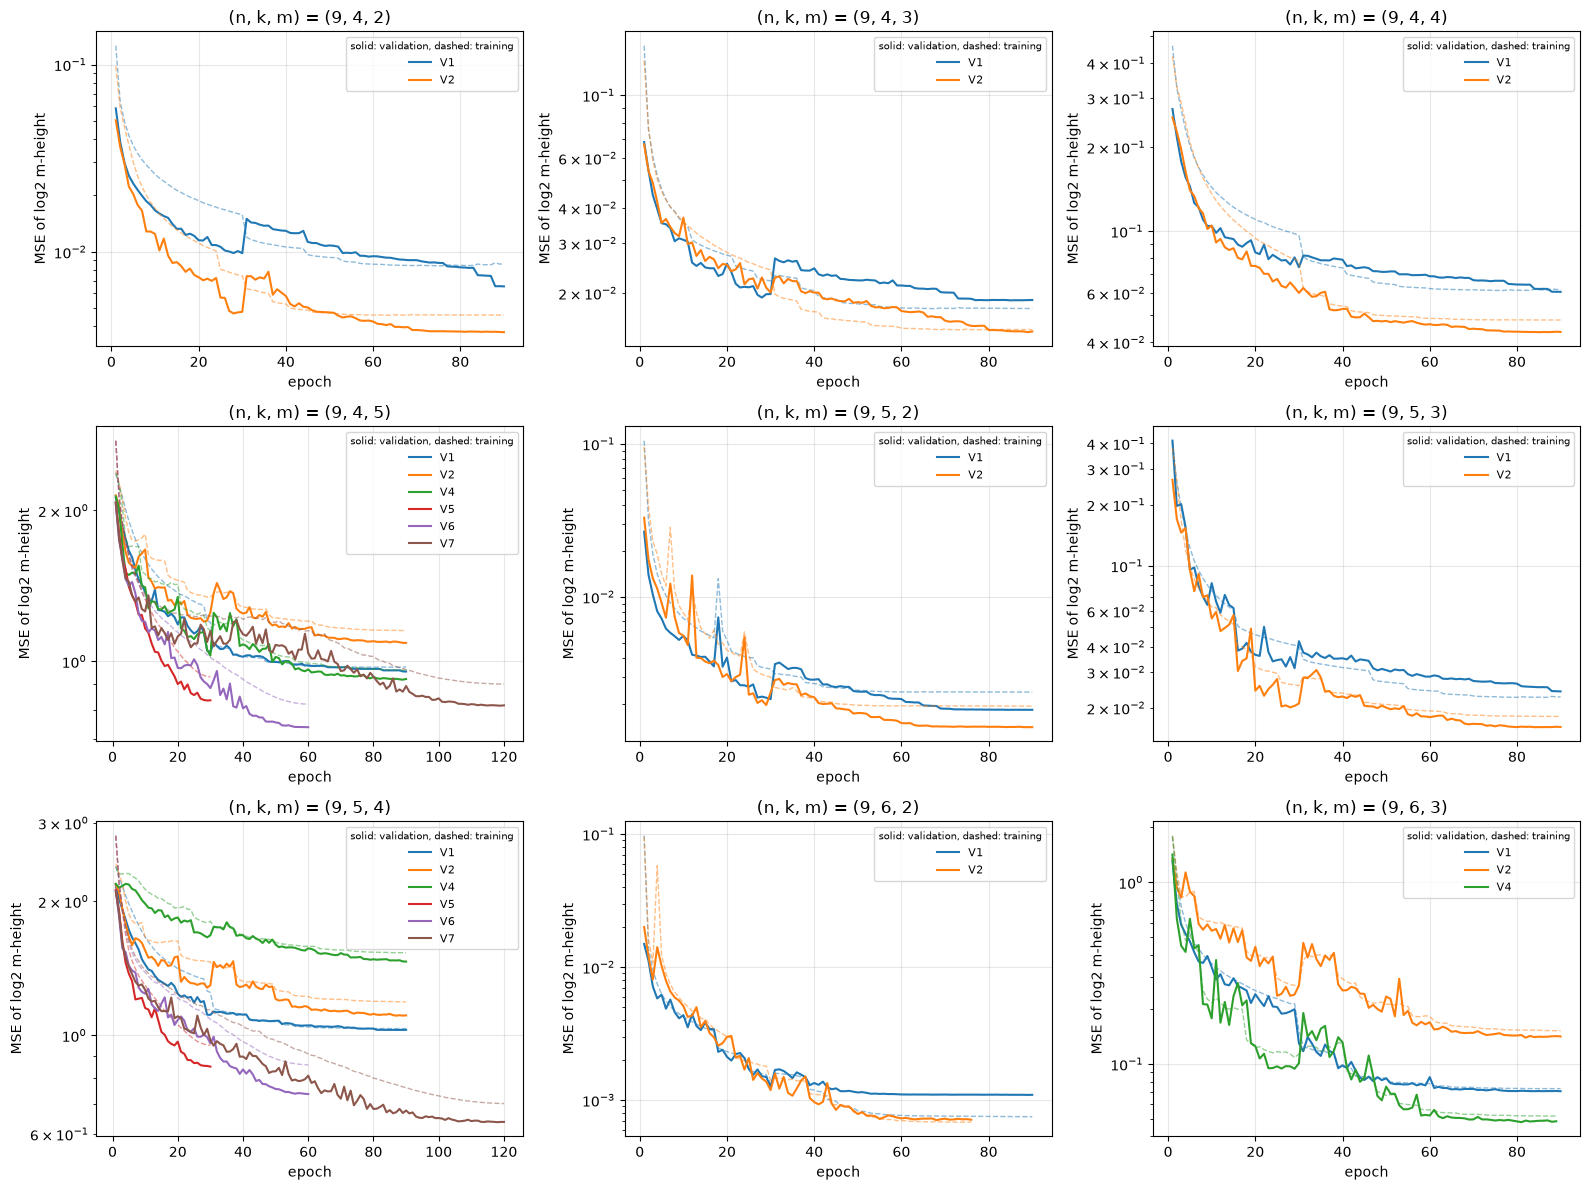

In [9]:
COLORS = dict(zip(VERSIONS, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, setting in zip(axes.ravel(), SETTINGS_ALL):
    shown = [v for v in VERSIONS if f"{v}_k{setting[1]}_m{setting[2]}_s0" in histories]
    if not shown:
        ax.set_visible(False)
        continue
    for v in shown:
        h = histories[f"{v}_k{setting[1]}_m{setting[2]}_s0"]
        epochs = np.arange(1, len(h["phase1"]["loss"]) + len(h["finetune"]["loss"]) + 1)
        ax.plot(epochs, h["phase1"]["val_loss"] + h["finetune"]["val_loss"], color=COLORS[v], label=v)
        ax.plot(epochs, h["phase1"]["loss"] + h["finetune"]["loss"], color=COLORS[v], linestyle="--", linewidth=1, alpha=0.5)
    ax.set_yscale("log"); ax.set_title(f"(n, k, m) = {setting}"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE of log2 m-height")
    ax.grid(alpha=0.3); ax.legend(fontsize=8, title="solid: validation, dashed: training", title_fontsize=7)
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=120)
plt.show()


## 7. Choosing the Network for Each Setting

Every trained version is scored on the provided **validation** rows of each setting it was trained for, with the cost $\sigma_{n,k,m}$. Predictions are made exactly as in the final cell: on the CPU, in batches of 1,024, with an XLA-compiled forward pass. Each setting then uses the version with the lowest validation cost. The test rows are not used here.


In [10]:
def predict_log2(network, X, params):
    @tf.function(jit_compile=True)
    def forward(batch):
        return network(batch, training=False)
    out = np.empty(len(X))
    with tf.device("/CPU:0"):
        for s in range(0, len(X), 1024):
            out[s:s + 1024] = np.asarray(forward({"matrix": X[s:s + 1024], "parameters": params[s:s + 1024]})).reshape(-1)
    return out


def version_network(version, k, m):
    """The trained network of a version for one setting: an Average layer over its seeds if MHEIGHT_SEEDS > 1."""
    members = [tf.keras.models.load_model(str(RUN_DIR / f"model_{version}_k{k}_m{m}_s{s}.keras"), compile=False)
               for s in range(SEEDS)]
    if SEEDS == 1:
        return members[0]
    ins = {"matrix": tf.keras.Input((6, 5), name="matrix"), "parameters": tf.keras.Input((3,), name="parameters")}
    for i, mem in enumerate(members):
        mem.name = f"seed_{i}"
    return tf.keras.Model(ins, tf.keras.layers.Average(name="log2_height")([mem(ins) for mem in members]))


networks, validation_cost, NETWORK = {}, {}, {}
for setting in SETTINGS:
    n, k, m = setting; g = SETTINGS_ALL.index(setting)
    rows = np.flatnonzero((setting_of == g) & (partition == 1))
    params = np.tile(np.float32(setting), (len(rows), 1))
    for version in VERSIONS:
        if setting not in VERSIONS[version]["settings"] or not (RUN_DIR / f"model_{version}_k{k}_m{m}_s0.keras").exists():
            continue
        with tf.device("/CPU:0"):
            networks[setting, version] = version_network(version, k, m)
        z = predict_log2(networks[setting, version], provided_P[rows], params)
        validation_cost[setting, version] = float(np.mean((np.log2(labels[rows]) - z) ** 2))
    if any(s == setting for s, v in validation_cost):
        NETWORK[setting] = min((v for s, v in validation_cost if s == setting), key=lambda v: validation_cost[setting, v])

print("Validation cost of every version (* = lowest, the version used):")
print(f"{'setting':11s}" + "".join(f"{v:>10s}" for v in VERSIONS) + "   used")
for setting in NETWORK:
    entries = [(f"{validation_cost[setting, v]:.4f}" + ("*" if v == NETWORK[setting] else " ")) if (setting, v) in validation_cost
             else "" for v in VERSIONS]
    print(f"{str(setting):11s}" + "".join(f"{e:>10s}" for e in entries) + f"   {NETWORK[setting]}")


I0000 00:00:1793229865.459344  251543 service.cc:153] XLA service 0x55fbfc055280 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793229865.459373  251543 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1793229865.612256  251543 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


I0000 00:00:1793229866.286333  251543 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Validation cost of every version (* = lowest, the version used):
setting            V1        V2        V4        V5        V6        V7   used
(9, 4, 2)     0.0065    0.0037*                                           V2
(9, 4, 3)     0.0189    0.0145*                                           V2
(9, 4, 4)     0.0606    0.0435*                                           V2
(9, 4, 5)     0.9538    1.0871    0.9167    0.8318    0.7347*   0.8120    V6
(9, 5, 2)     0.0018    0.0014*                                           V2
(9, 5, 3)     0.0241    0.0159*                                           V2
(9, 5, 4)     1.0278    1.1030    1.4641    0.8460    0.7339    0.6337*   V7
(9, 6, 2)     0.0011    0.0007*                                           V2
(9, 6, 3)     0.0707    0.1356    0.0442*                                 V4


**How the versions progressed** (validation costs from the table above):
- **V1 → V2.** Attention (V2) is more accurate than row and column means (V1) in the six settings with $m < n - k$. V1 stays more accurate in the three settings with $m = n - k$, where both are by far the least accurate.
- **V3** chose, for each setting, the better of V1 and V2.
- **V4.** The larger transformer is the most accurate so far for (9, 4, 5) and (9, 6, 3). For (9, 5, 4), with its learning rate at its peak from the first step, it stayed near the constant prediction for the first epochs and never caught up.
- **V5.** A warm-up and a cosine decay of the learning rate avoid that stall, and give the best costs yet for both (9, 4, 5) and (9, 5, 4).
- **V6.** The same schedule over 60 epochs lowers both costs further.
- **V7.** Over 120 epochs, (9, 5, 4) improves again. (9, 4, 5) instead gets worse: while the learning rate was still near its peak, its training loss stayed near 1.22 for about 30 epochs (section 6), and it ended with a higher training loss than V6, so it underfits rather than overfits.

**The networks used:** V2 for (9, 4, 2), (9, 4, 3), (9, 4, 4), (9, 5, 2), (9, 5, 3) and (9, 6, 2); V4 for (9, 6, 3); V6 for (9, 4, 5); and V7 for (9, 5, 4).


## 8. The Final Model and Its Performance

**One final model.** The network chosen for each setting in section 7 is saved as `final_k{k}_m{m}.keras`, and the 9 of them are joined into a single Keras model, `final_model_v7.keras`, which is the submitted network:
1. **Selection mask:** from the input $[n, k, m]$, a fixed `Dense` layer computes $\pm(k - k_s)$ and $\pm(m - m_s)$ for each setting $s$. `ReLU` turns these into $|k - k_s|$ and $|m - m_s|$, and a second fixed `Dense` + `ReLU` computes $\max(0,\ 1 - |k-k_s| - |m-m_s|)$. Because $k$ and $m$ are integers, this is exactly 1 for the sample's own setting and 0 for the other eight.
2. **Networks:** all 9 chosen networks run on the sample, as sub-models.
3. **Output:** their outputs are multiplied by the mask (`Multiply`) and summed (`Dense` with weights 1), so the output is the $\log_2$ prediction of the sample's own network, still in $[0, 100]$.

The cell checks that `final_model_v7.keras` gives the same predictions as the 9 chosen networks.

**Performance** is the cost $\sigma_{n,k,m}$ of `final_model_v7.keras` on the provided **validation** rows (used to choose epochs and versions) and on the held-out **test** rows (used only here), together with the mean over the 9 settings. Predictions are made exactly as in the final cell (on the CPU, in batches of 1,024, with an XLA-compiled forward pass).


In [11]:
def combine_settings(paths):
    """One model: a fixed one-hot mask over the 9 settings selects the matching network's output."""
    ins = {"matrix": tf.keras.Input((6, 5), name="matrix"), "parameters": tf.keras.Input((3,), name="parameters")}
    W1, b1 = np.zeros((3, 4 * len(SETTINGS_ALL))), np.zeros(4 * len(SETTINGS_ALL))
    W2, b2 = np.zeros((4 * len(SETTINGS_ALL), len(SETTINGS_ALL))), np.ones(len(SETTINGS_ALL))
    for i, (n, k, m) in enumerate(SETTINGS_ALL):
        for j, (row, sign, target) in enumerate([(1, 1, k), (1, -1, k), (2, 1, m), (2, -1, m)]):
            W1[row, 4 * i + j], b1[4 * i + j] = sign, -sign * target          # +-(k - k_s), +-(m - m_s)
            W2[4 * i + j, i] = -1.0                                           # 1 - |k-k_s| - |m-m_s|
    diffs = tf.keras.layers.Dense(len(b1), activation="relu", kernel_initializer=const(W1), bias_initializer=const(b1),
                                  name="setting_differences")(ins["parameters"])
    mask = tf.keras.layers.Dense(len(b2), activation="relu", kernel_initializer=const(W2), bias_initializer=const(b2),
                                 name="setting_mask")(diffs)
    outputs = []
    for (n, k, m), path in zip(SETTINGS_ALL, paths):
        member = tf.keras.models.load_model(str(path), compile=False)
        member.name = f"network_k{k}_m{m}"
        outputs.append(member(ins))
    chosen = tf.keras.layers.Multiply()([mask, tf.keras.layers.Concatenate()(outputs)])
    out = tf.keras.layers.Dense(1, use_bias=False, kernel_initializer="ones", name="log2_height")(chosen)
    return tf.keras.Model(ins, out, name="mheight_final")


report = {}
for setting, version in NETWORK.items():
    n, k, m = setting
    with tf.device("/CPU:0"):
        networks[setting, version].save(RUN_DIR / f"final_k{k}_m{m}.keras")

setting_files = [RUN_DIR / f"final_k{k}_m{m}.keras" for n, k, m in SETTINGS_ALL]
if all(path.exists() for path in setting_files):
    with tf.device("/CPU:0"):
        combine_settings(setting_files).save(RUN_DIR / "final_model_v7.keras")
        evaluated = tf.keras.models.load_model(str(RUN_DIR / "final_model_v7.keras"), compile=False)
    print(f"Saved {RUN_DIR / 'final_model_v7.keras'} ({evaluated.count_params():,} parameters)")
else:
    evaluated = None
    print("Not all 9 settings are trained yet; evaluating the per-setting networks of this run")

for setting in NETWORK:
    n, k, m = setting; g = SETTINGS_ALL.index(setting)
    with tf.device("/CPU:0"):
        own = tf.keras.models.load_model(str(RUN_DIR / f"final_k{k}_m{m}.keras"), compile=False)
    report[str(setting)] = {"version": NETWORK[setting]}
    for split, p in (("validation", 1), ("test", 2)):
        rows = np.flatnonzero((setting_of == g) & (partition == p))
        params = np.tile(np.float32(setting), (len(rows), 1))
        z = predict_log2(evaluated or own, provided_P[rows], params)
        if evaluated is not None and split == "validation":
            gap = np.abs(z - predict_log2(own, provided_P[rows], params)).max()
            print(f"{setting}: final_model_v7.keras matches the per-setting network (max |difference| {gap:.1e})")
        report[str(setting)][split] = float(np.mean((np.log2(labels[rows]) - z) ** 2))
    print(f"{setting} {NETWORK[setting]}: validation sigma {report[str(setting)]['validation']:.4f} | "
          f"test sigma {report[str(setting)]['test']:.4f}")
done = [report[str(s)] for s in NETWORK]
print(f"\nMean over {len(done)} settings: validation {np.mean([r['validation'] for r in done]):.4f} | "
      f"test {np.mean([r['test'] for r in done]):.4f}")
(RUN_DIR / "costs.json").write_text(json.dumps(report, indent=2))


Saved artifacts/p2_v7_all/final_model_v7.keras (13,012,362 parameters)


(9, 4, 2): final_model_v7.keras matches the per-setting network (max |difference| 0.0e+00)


(9, 4, 2) V2: validation sigma 0.0037 | test sigma 0.0039


(9, 4, 3): final_model_v7.keras matches the per-setting network (max |difference| 0.0e+00)


(9, 4, 3) V2: validation sigma 0.0145 | test sigma 0.0143


...

(9, 6, 2): final_model_v7.keras matches the per-setting network (max |difference| 0.0e+00)


(9, 6, 2) V2: validation sigma 0.0007 | test sigma 0.0010


(9, 6, 3): final_model_v7.keras matches the per-setting network (max |difference| 0.0e+00)


(9, 6, 3) V4: validation sigma 0.0442 | test sigma 0.0512

Mean over 9 settings: validation 0.1658 | test 0.1690


1040

## 9. Final Cell: Predict m-Heights for a Test File

This is the cell for testing the trained model. It is **self-contained** - in a fresh session, run only this cell. On Colab it first installs the pinned TensorFlow/Keras versions. No training cells or training data are needed.

1. Place the trained model `final_model_v7.keras` next to this notebook. When run from the project folder, the cell also finds it in `artifacts/submission/`.
2. Set `TEST_INPUT_PATH` to the test file: a pickled list of samples `[n, k, m, P]`, in the same format as `CSCE-636-Project-2-Train-n_k_m_P`.
3. Run the cell. It writes `OUTPUT_PATH`: a pickled list of predicted m-heights (Python floats), one per input sample in the same order, in the same format as `CSCE-636-Project-2-Train-mHeights`.

$P$ is placed in a zero-padded $6 \times 5$ array, and $[n, k, m]$ is passed alongside it. Inside the model, each sample is handled by the network of its $(k, m)$. The model outputs $z = \log_2 \hat y \in [0, 100]$, and the only post-processing is $\hat y = 2^z$, so every prediction is finite and at least 1. The cell checks this before saving. Inside the cell, each group of samples is run through the network of its setting only (identical outputs, about 9 times faster than evaluating every network). Inference runs on the CPU in fixed batches of 1024, compiled with XLA, so repeated runs on one machine give identical results. `USE_GPU = True` makes it faster on a GPU runtime, but GPU arithmetic can differ from the CPU in the last digits, so the CPU is used for predictions that are submitted.


In [ ]:
# ===== Final cell: load the trained DNNs and predict m-heights for a test file =====
# On Google Colab, first install the package versions used for training, so the saved networks load and
# predict identically (elsewhere the project environment is used).
import sys

if "google.colab" in sys.modules:
    %pip install -q "numpy>=2,<3" "tensorflow==2.21.0" "keras==3.15.1"

import pickle
from pathlib import Path

import numpy as np
import tensorflow as tf

if "google.colab" in sys.modules and tf.__version__ != "2.21.0":
    raise RuntimeError(f"TensorFlow {tf.__version__} was already loaded: restart the runtime (Runtime > Restart session) and run this cell again.")

TEST_INPUT_PATH = "CSCE-636-Project-2-Test-n_k_m_P"   # pickled list of [n, k, m, P]
OUTPUT_PATH = "CSCE-636-Project-2-Test-mHeights"      # pickled list of predicted m-heights
MODEL_FILES = ["final_model_v7.keras", "artifacts/submission/final_model_v7.keras"]
BATCH = 1024
USE_GPU = False   # True: faster on a GPU runtime; CPU (default) reproduces submitted predictions exactly


class CompatUnpickler(pickle.Unpickler):
    # Pickles written with NumPy 2 reference numpy._core; NumPy 1.x only has numpy.core.
    def find_class(self, module, name):
        if int(np.__version__.split(".")[0]) < 2 and module.startswith("numpy._core"):
            module = "numpy.core" + module[len("numpy._core"):]
        return super().find_class(module, name)


if not Path(TEST_INPUT_PATH).exists():
    # Nothing to predict yet (e.g. a batch run before the test file is available).
    print(f"Test file {TEST_INPUT_PATH!r} not found: set TEST_INPUT_PATH and run this cell again.")
else:
    model_file = next((path for path in MODEL_FILES if Path(path).exists()), None)
    if model_file is None:
        raise FileNotFoundError(f"Trained model not found; looked for {MODEL_FILES}")
    device = "/GPU:0" if USE_GPU and tf.config.list_physical_devices("GPU") else "/CPU:0"
    with tf.device(device):
        network = tf.keras.models.load_model(model_file, compile=False)

    with open(TEST_INPUT_PATH, "rb") as file:
        samples = CompatUnpickler(file).load()

    # Inputs: P in the upper-left corner of a zero-padded 6 x 5 array, and [n, k, m].
    matrices = np.zeros((len(samples), 6, 5), dtype=np.float32)
    parameters = np.zeros((len(samples), 3), dtype=np.float32)
    for row, (n, k, m, P) in enumerate(samples):
        P = np.asarray(P, dtype=np.float64)
        if P.shape != (k, n - k):
            raise ValueError(f"Sample {row}: P has shape {P.shape}, expected {(k, n - k)}")
        matrices[row, :k, :n - k] = P
        parameters[row] = (n, k, m)

    # final_model_v7.keras selects, for every sample, the output of the network of its (k, m). Running each
    # group of samples through that network alone gives identical outputs and avoids evaluating all 9.
    log2_heights = np.full(len(samples), np.nan)
    for k, m in sorted({(int(p[1]), int(p[2])) for p in parameters}):
        rows = np.flatnonzero((parameters[:, 1] == k) & (parameters[:, 2] == m))
        setting_network = network.get_layer(f"network_k{k}_m{m}")

        @tf.function(jit_compile=True)
        def predict(batch):
            return setting_network(batch, training=False)

        with tf.device(device):
            for start in range(0, len(rows), BATCH):
                selected = rows[start:start + BATCH]
                batch = {"matrix": matrices[selected], "parameters": parameters[selected]}
                log2_heights[selected] = np.asarray(predict(batch)).reshape(-1)
    predicted_heights = np.exp2(log2_heights)

    if len(predicted_heights) != len(samples) or not np.isfinite(predicted_heights).all() \
            or np.any(predicted_heights < 1):
        raise ValueError("Every prediction must be finite and at least 1; nothing was saved")
    with open(OUTPUT_PATH, "wb") as file:
        pickle.dump(predicted_heights.tolist(), file)
    print(f"Model: {model_file} | predicted {len(predicted_heights):,} m-heights -> {OUTPUT_PATH} (TensorFlow {tf.__version__})")
    print(f"Range: {predicted_heights.min():.4f} to {predicted_heights.max():.4f}; first five: {predicted_heights[:5].tolist()}")
